In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

In [7]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print(x_train.shape, y_train.shape)

(60000, 28, 28) (60000,)


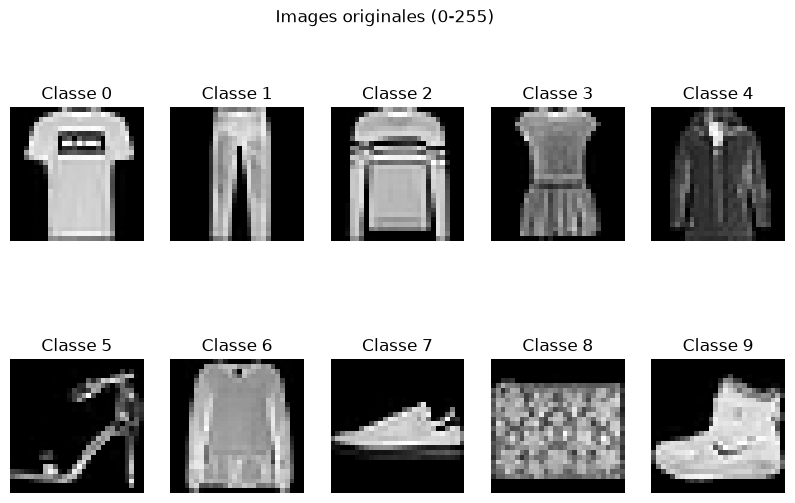

In [8]:
plt.figure(figsize=(10, 6))

for digit in range(10):
    idx = np.where(y_train == digit)[0][0]
    plt.subplot(2, 5, digit + 1)
    plt.imshow(x_train[idx], cmap="gray")
    plt.axis("off")
    plt.title(f"Classe {digit}")

plt.suptitle("Images originales (0-255)")
plt.show()

In [9]:
X_train = x_train.astype("float32") / 255.0
X_test = x_test.astype("float32") / 255.0

In [10]:
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print("Formes finales :", X_train.shape, X_test.shape)

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


In [11]:
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

In [12]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 3, 3, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.7662 - loss: 0.6442 - val_accuracy: 0.8472 - val_loss: 0.4105
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8552 - loss: 0.4032 - val_accuracy: 0.8747 - val_loss: 0.3309
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8784 - loss: 0.3408 - val_accuracy: 0.8857 - val_loss: 0.2934
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8890 - loss: 0.3071 - val_accuracy: 0.8927 - val_loss: 0.2877
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8996 - loss: 0.2809 - val_accuracy: 0.8957 - val_loss: 0.2725


In [15]:
loss, acc = model.evaluate(X_test, y_test, verbose=2)

print(f"Précision sur le test : {acc * 100:.2f}%")

313/313 - 1s - 3ms/step - accuracy: 0.8940 - loss: 0.2848
Précision sur le test : 89.40%


In [16]:
y_pred = np.argmax(model.predict(X_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


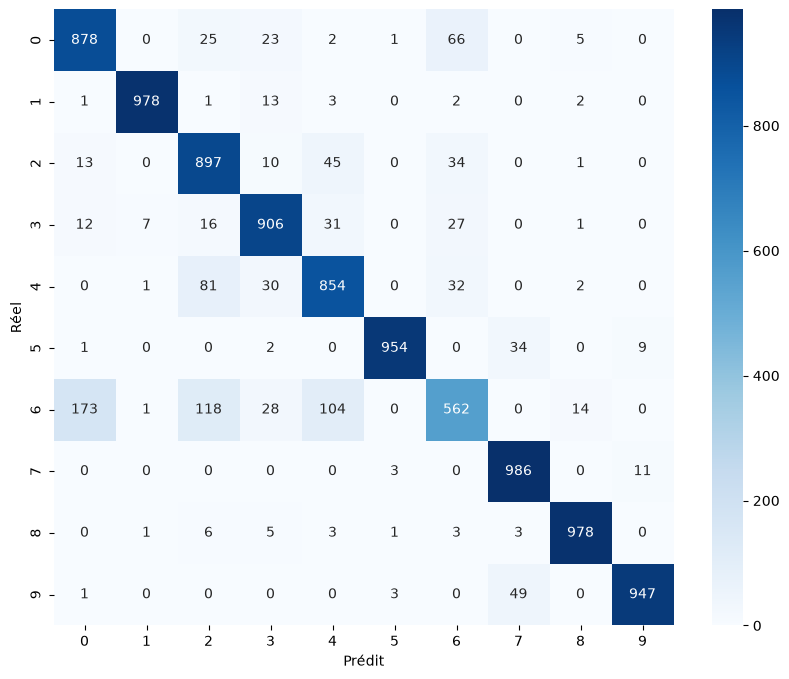

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

In [18]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.88      0.84      1000
           1       0.99      0.98      0.98      1000
           2       0.78      0.90      0.84      1000
           3       0.89      0.91      0.90      1000
           4       0.82      0.85      0.84      1000
           5       0.99      0.95      0.97      1000
           6       0.77      0.56      0.65      1000
           7       0.92      0.99      0.95      1000
           8       0.98      0.98      0.98      1000
           9       0.98      0.95      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



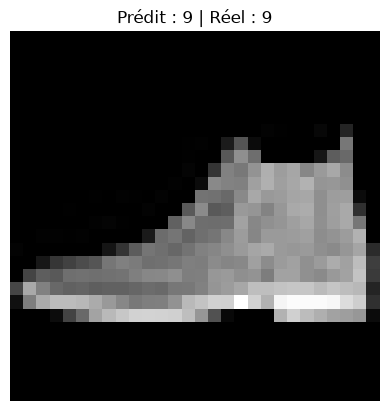

In [19]:
plt.imshow(X_test[0].reshape(28, 28), cmap="gray")
plt.title(f"Prédit : {y_pred[0]} | Réel : {y_test[0]}")
plt.axis("off")
plt.show()

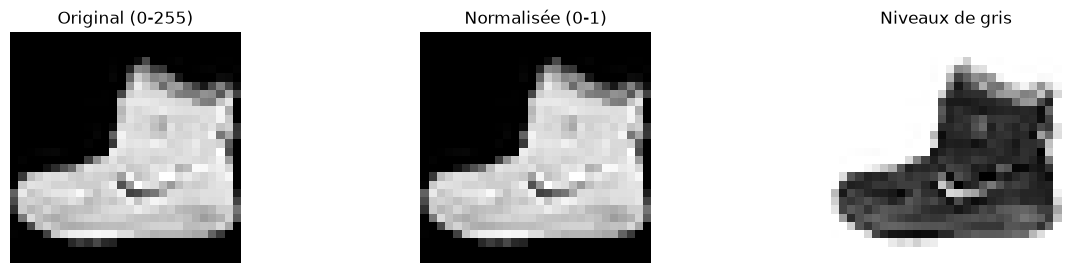

In [20]:
img = x_train[0]

plt.figure(figsize=(15, 3))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original (0-255)")
plt.axis("off")

img_norm = img.astype("float32") / 255.0

plt.subplot(1, 3, 2)
plt.imshow(img_norm, cmap="gray")
plt.title("Normalisée (0-1)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_norm, cmap="Greys")
plt.title("Niveaux de gris")
plt.axis("off")

plt.show()

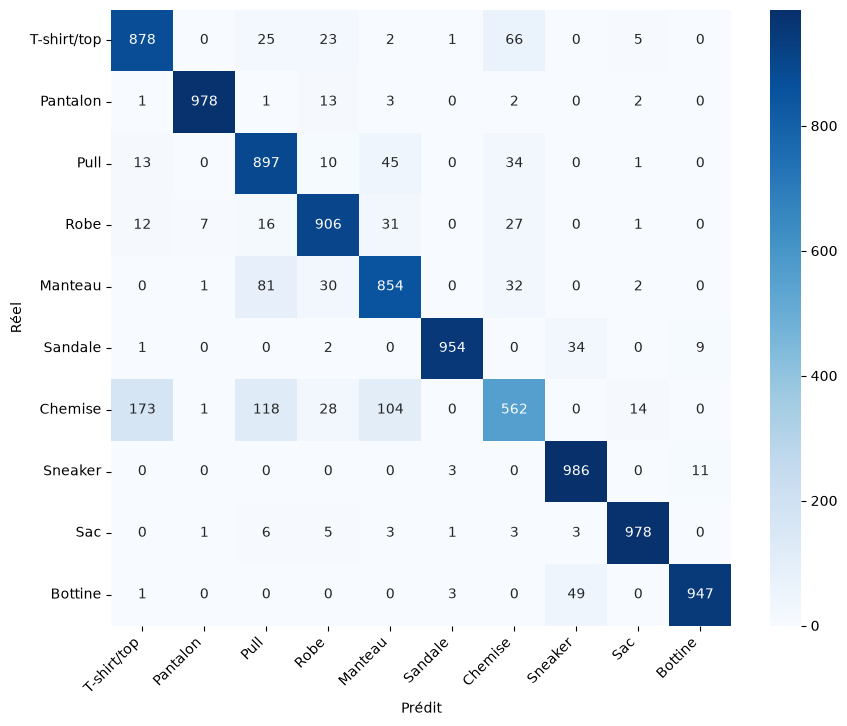

In [21]:
classes = ["T-shirt/top", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Sneaker", "Sac", "Bottine"]

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)

plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.xticks(rotation=45, ha="right")
plt.show()